# XRP Price and Volatility Analysis
Lukash Shrestha

Exploratory analysis of daily XRP/USD price data: data cleaning, daily returns, rolling volatility and visualization. Data: `XRP.csv`, downloaded from Kaggle.

In [ ]:
import numpy as np
import pandas as pd
import os

In [ ]:
# Commented out IPython magic to ensure Python compatibility.
import matplotlib.pyplot as plt
# %matplotlib inline
import seaborn as sns
print("All pkgs have been imported successfully.")

All pkgs have been imported successfully.


In [ ]:
dfXRP = pd.read_csv("XRP.csv")
dfXRP['Date'] = pd.to_datetime(dfXRP['Date'])
dfXRP = dfXRP.sort_values('Date').reset_index(drop=True)
dfXRP.head()

,Date,High,Low,Open,Close,Volume,Adj Close
0,2014-09-16,0.005803,0.005123,0.005123,0.005399,1281960,0.005399
1,2014-09-17,0.005521,0.005091,0.005398,0.005135,491147,0.005135
2,2014-09-18,0.005167,0.004873,0.005134,0.004942,407109,0.004942
3,2014-09-19,0.004954,0.004736,0.004942,0.004772,322621,0.004772
4,2014-09-20,0.004791,0.004540,0.004768,0.004570,309571,0.004570


In [ ]:
nRow,nCol = dfXRP.shape

In [ ]:
nRow, nCol = dfXRP.shape
print("Number of columns in the dataset =",nCol)
print("Number of rows in the dataset    =",nRow)
print("Is there any null value in the dataset ?",dfXRP.isnull().values.any())

Number of columns in the dataset = 7
Number of rows in the dataset    = 837
Is there any null value in the dataset ? False


In [ ]:
print("Display a column-wise null value count\n")
dfXRP.isnull().sum()

Display a column-wise null value count



,0
Date,0
High,0
Low,0
Open,0
Close,0
Volume,0
Adj Close,0


In [ ]:
print("Getting rid of the null data")
dfXRP.dropna(inplace=True)
dfXRP.head(10)

Getting rid of the null data


,Date,High,Low,Open,Close,Volume,Adj Close
0,2014-09-16,0.005803,0.005123,0.005123,0.005399,1281960,0.005399
1,2014-09-17,0.005521,0.005091,0.005398,0.005135,491147,0.005135
2,2014-09-18,0.005167,0.004873,0.005134,0.004942,407109,0.004942
3,2014-09-19,0.004954,0.004736,0.004942,0.004772,322621,0.004772
4,2014-09-20,0.004791,0.004540,0.004768,0.004570,309571,0.004570
5,2014-09-21,0.004670,0.004532,0.004561,0.004657,267342,0.004657
6,2014-09-22,0.004656,0.004547,0.004655,0.004613,323106,0.004613
7,2014-09-23,0.004668,0.004511,0.004610,0.004668,349329,0.004668
8,2014-09-24,0.004850,0.004642,0.004670,0.004722,745348,0.004722
9,2014-09-25,0.004734,0.004558,0.004722,0.004616,497323,0.004616


In [ ]:
print("Number of null values dropped =",nRow - len(dfXRP))

Number of null values dropped = 0


In [ ]:
##print(datesArr,"\n")

In [ ]:
x = dfXRP['Open'].values
x1 = dfXRP['Close'].values
x2 = dfXRP['High'].values
x3 = dfXRP['Low'].values

In [ ]:
print("These are the open values")
print(x,"\n")

These are the open values
[0.00512251 0.00539815 0.00513386 0.00494179 0.00476827 0.00456111
 0.0046552  0.00460974 0.00466996 0.00472183 0.00460747 0.00470576
 0.00527948 0.00470523 0.00464498 0.00475516 0.00487602 0.00502388
 0.00493456 0.00477738 0.00473096 0.00476936 0.00478738 0.00482412
 0.0048732  0.00475445 0.00485316 0.00479398 0.00487182 0.00482495
 0.00485525 0.00490429 0.0049642  0.00494538 0.00507192 0.00518983
 0.00518517 0.00514275 0.00508271 0.00471978 0.00454632 0.00489044
 0.00484033 0.00477433 0.00488716 0.00486518 0.00467368 0.0046584
 0.00480949 0.00480606 0.0048611  0.00487793 0.00487686 0.00490441
 0.00491962 0.00489649 0.00489665 0.00512798 0.00502243 0.00520626
 0.00503916 0.00518078 0.00533749 0.00542353 0.00569267 0.00607171
 0.00659095 0.00766919 0.00859513 0.00856136 0.00974221 0.011004
 0.014201   0.0151604  0.0139772  0.0112038  0.0125865  0.0131643
 0.013137   0.0133362  0.0137713  0.014406   0.0147929  0.0134179
 0.0150706  0.0158852  0.0163741  0.01637

In [ ]:
print("These are the close values")
print(x1,"\n")

These are the close values
[0.00539852 0.00513545 0.00494225 0.00477165 0.00456989 0.00465728
 0.00461318 0.00466761 0.00472228 0.00461558 0.00470504 0.00528196
 0.00470454 0.00464397 0.00475239 0.00487409 0.00502282 0.00494149
 0.00478866 0.00472994 0.00476536 0.00478661 0.0048238  0.00487145
 0.00475305 0.00485764 0.00478419 0.00487153 0.00482708 0.00485466
 0.00490406 0.00496506 0.00494914 0.0050735  0.00519264 0.00518732
 0.0051418  0.00508175 0.00471925 0.00454788 0.0048914  0.00484465
 0.00477601 0.00488997 0.00486669 0.00467086 0.00466442 0.0048102
 0.00480483 0.00486105 0.00487745 0.00487711 0.00490699 0.00492611
 0.00490147 0.0048986  0.0050974  0.00503508 0.00519666 0.00505247
 0.00518113 0.0053397  0.00543151 0.00569554 0.00605795 0.00658929
 0.00766316 0.00859941 0.00856188 0.00974036 0.0110036  0.0142048
 0.0151648  0.0139819  0.0112114  0.0125585  0.0131579  0.0131302
 0.0133431  0.0137849  0.0144061  0.0147942  0.0134206  0.0150682
 0.0159075  0.0163741  0.0163741  0.016

In [ ]:
print("These are the high values")
print(x2,"\n")

These are the high values
[0.00580299 0.00552101 0.00516744 0.00495388 0.00479126 0.00467029
 0.00465607 0.00466761 0.00485033 0.00473408 0.00471691 0.00534516
 0.00544205 0.00470739 0.00477234 0.00487626 0.00504966 0.00520448
 0.00501199 0.00478704 0.00480584 0.00480551 0.0048786  0.00487644
 0.00488138 0.00486687 0.00486707 0.00492964 0.00488148 0.00485844
 0.00490967 0.00498517 0.00498942 0.00508328 0.00521586 0.00522028
 0.00524256 0.00515367 0.00508739 0.00472118 0.00492013 0.00489382
 0.00484808 0.00491018 0.00490397 0.00487928 0.00472267 0.00481114
 0.00485944 0.00487164 0.00489826 0.00489463 0.00491371 0.00494111
 0.00495641 0.00490632 0.00520899 0.00529723 0.00519666 0.00522942
 0.00520539 0.00537771 0.00544913 0.00569555 0.00609596 0.0066032
 0.00775991 0.00877289 0.00879123 0.00984093 0.0110138  0.0142053
 0.0152966  0.0151604  0.0139772  0.0125723  0.013307   0.0131852
 0.0133478  0.0137982  0.0144124  0.0147942  0.015188   0.0150707
 0.0159332  0.0163741  0.0163741  0.0171

In [ ]:
print("These are the low values")
print(x3,"\n")

These are the low values
[0.00512251 0.00509103 0.00487314 0.00473589 0.00453999 0.00453249
 0.00454722 0.00451145 0.00464191 0.00455789 0.00457538 0.00465014
 0.00465835 0.00463481 0.00464432 0.00475347 0.00487527 0.00493095
 0.00474609 0.00470729 0.00472672 0.00469939 0.00477002 0.00481368
 0.00474788 0.00474445 0.00472046 0.0047905  0.00479108 0.00477617
 0.00482435 0.00489207 0.00492313 0.00492144 0.00506877 0.00517625
 0.00513442 0.00507054 0.00471224 0.00452478 0.00453363 0.00461557
 0.00474552 0.00476884 0.00484856 0.00463573 0.00463766 0.0046523
 0.00478046 0.00480606 0.00483392 0.00485395 0.00487686 0.00488033
 0.00488574 0.00487308 0.00489665 0.00490965 0.00489592 0.00501566
 0.00503916 0.00518078 0.00533749 0.00542353 0.00569247 0.00603742
 0.00659095 0.00766919 0.00836152 0.00856136 0.00969482 0.011004
 0.0137571  0.0139819  0.0111819  0.00810471 0.012568   0.0129178
 0.013137   0.0133112  0.0137261  0.0143876  0.0131902  0.0132683
 0.0150147  0.0158051  0.0163741  0.016374

In [ ]:
print("These are the volume XRP values")

These are the volume XRP values


In [ ]:
y = dfXRP['Volume'].values
print(y,"\n")

[ 1281960   491147   407109   322621   309571   267342   323106   349329
   745348   497323   221573   464102   122073   109352    64998   209158
   264083   168516   181316   218684   136439   398026   214591   140436
   263175   272667   463679   231490   235627   119623   245692    69145
    55747   295888   146796   107561   378216   282070   272566   440679
   299518   272894   346606   220063   151046   190204   119913   212517
   276134   309820   416386   434075   143181   240824   545390   781614
   447173   486595   300910   116803    78345   431359   454544   434916
   932564   720035  1123560  1288050   836154  2617990  2382860  5355350
  2815520  1878500  2857340  3453750  2206040  1063000  2363160  1281290
  1402450   935386  2568380  1621600  1116220  1620910  1620910  1210950
   431814  2633740  6249780  5981140  4016710  6254590  3224770  1523180
  2150370  2778770  1428390  1234800  2011780   837992  1005650  1145800
   795505   640940   399022   459956  2171040  3801

In [ ]:
print("These are the adjusted close values")

These are the adjusted close values


In [ ]:
y1 = dfXRP['Adj Close'].values
print(y1,"\n")

[0.00539852 0.00513545 0.00494225 0.00477165 0.00456989 0.00465728
 0.00461318 0.00466761 0.00472228 0.00461558 0.00470504 0.00528196
 0.00470454 0.00464397 0.00475239 0.00487409 0.00502282 0.00494149
 0.00478866 0.00472994 0.00476536 0.00478661 0.0048238  0.00487145
 0.00475305 0.00485764 0.00478419 0.00487153 0.00482708 0.00485466
 0.00490406 0.00496506 0.00494914 0.0050735  0.00519264 0.00518732
 0.0051418  0.00508175 0.00471925 0.00454788 0.0048914  0.00484465
 0.00477601 0.00488997 0.00486669 0.00467086 0.00466442 0.0048102
 0.00480483 0.00486105 0.00487745 0.00487711 0.00490699 0.00492611
 0.00490147 0.0048986  0.0050974  0.00503508 0.00519666 0.00505247
 0.00518113 0.0053397  0.00543151 0.00569554 0.00605795 0.00658929
 0.00766316 0.00859941 0.00856188 0.00974036 0.0110036  0.0142048
 0.0151648  0.0139819  0.0112114  0.0125585  0.0131579  0.0131302
 0.0133431  0.0137849  0.0144061  0.0147942  0.0134206  0.0150682
 0.0159075  0.0163741  0.0163741  0.0169923  0.0171268  0.0182415


In [ ]:
# Daily returns and 30-day rolling volatility, annualized (crypto trades every day)
dfXRP['Return'] = dfXRP['Close'].pct_change()
window = 30
dfXRP['Volatility'] = dfXRP['Return'].rolling(window).std() * np.sqrt(365)

print(f"Daily rows: {len(dfXRP)}")
print(f"Average annualized volatility: {dfXRP['Volatility'].mean():.2f}")
dfXRP[['Date', 'Close', 'Return', 'Volatility']].tail()

Daily rows: 837
Average annualized volatility: 0.78


,Date,Close,Return,Volatility
832,2016-12-27,0.006199,-0.020004,0.336762
833,2016-12-28,0.006173,-0.004252,0.336271
834,2016-12-29,0.006341,0.027180,0.337202
835,2016-12-30,0.006426,0.013532,0.340664
836,2016-12-31,0.006449,0.003497,0.341017


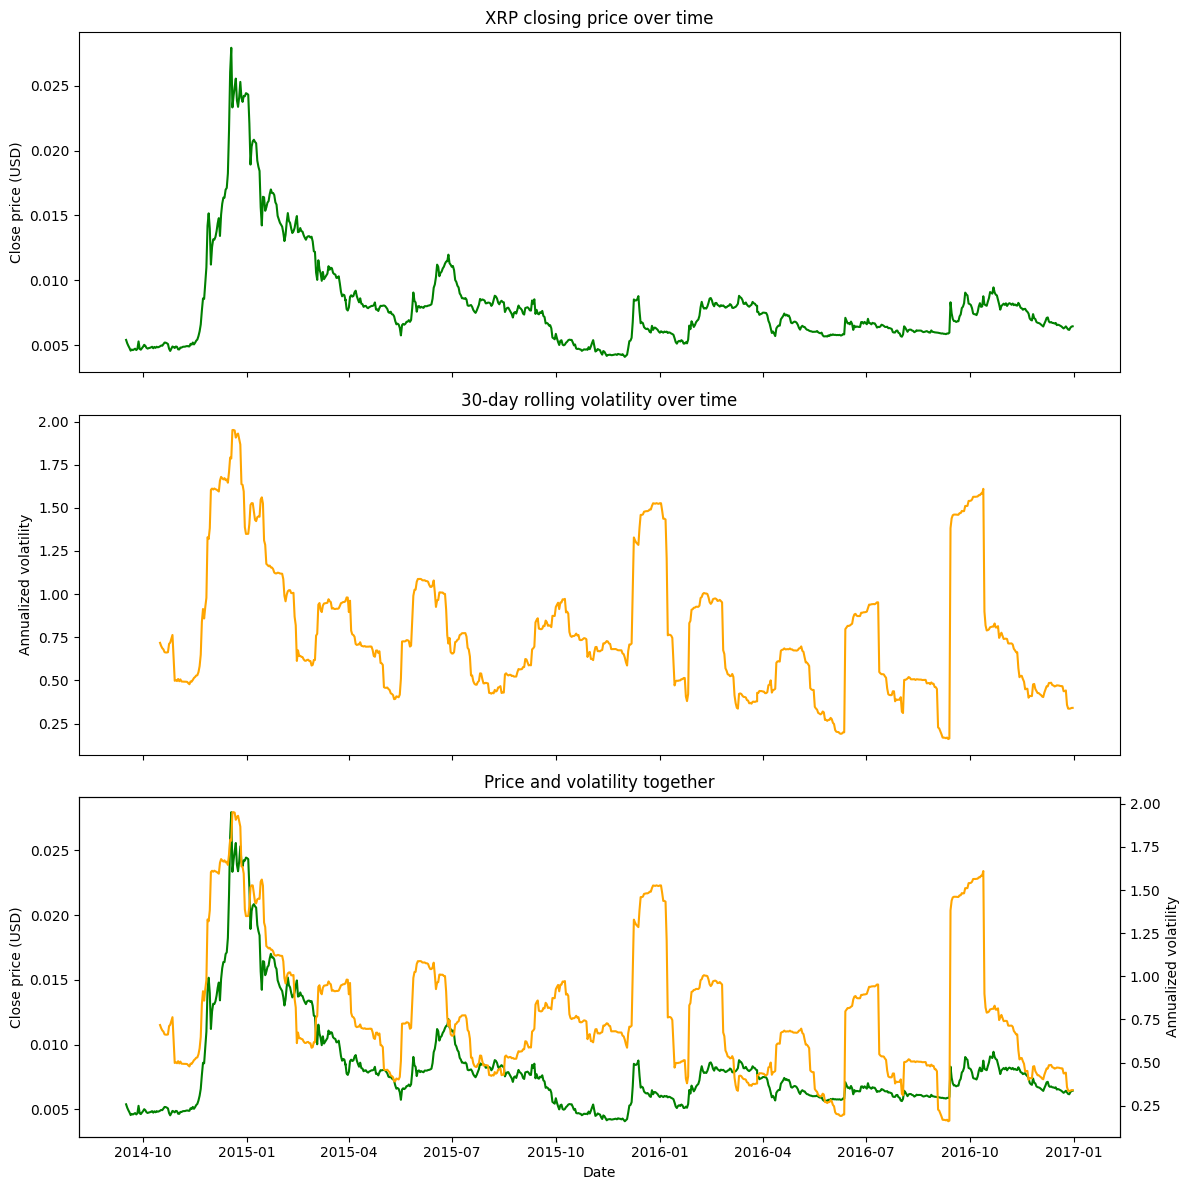

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(dfXRP['Date'], dfXRP['Close'], color='green')
axes[0].set_ylabel("Close price (USD)")
axes[0].set_title("XRP closing price over time")

axes[1].plot(dfXRP['Date'], dfXRP['Volatility'], color='orange')
axes[1].set_ylabel("Annualized volatility")
axes[1].set_title("30-day rolling volatility over time")

axes[2].plot(dfXRP['Date'], dfXRP['Close'], color='green')
axes[2].set_ylabel("Close price (USD)")
twin = axes[2].twinx()
twin.plot(dfXRP['Date'], dfXRP['Volatility'], color='orange')
twin.set_ylabel("Annualized volatility")
axes[2].set_title("Price and volatility together")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [ ]:
dfXRP[['Open', 'High', 'Low', 'Close', 'Volume']].describe()

,Open,High,Low,Close,Volume
count,837.000000,837.000000,837.000000,837.000000,8.370000e+02
mean,0.008123,0.008304,0.007962,0.008125,1.052281e+06
std,0.003791,0.003936,0.003663,0.003791,1.311940e+06
min,0.004091,0.004189,0.004041,0.004090,2.481800e+04
25%,0.005996,0.006062,0.005938,0.006000,3.507310e+05
50%,0.007282,0.007435,0.007095,0.007284,6.274750e+05
75%,0.008335,0.008579,0.008164,0.008337,1.181010e+06
max,0.027975,0.028034,0.025511,0.027940,1.596760e+07


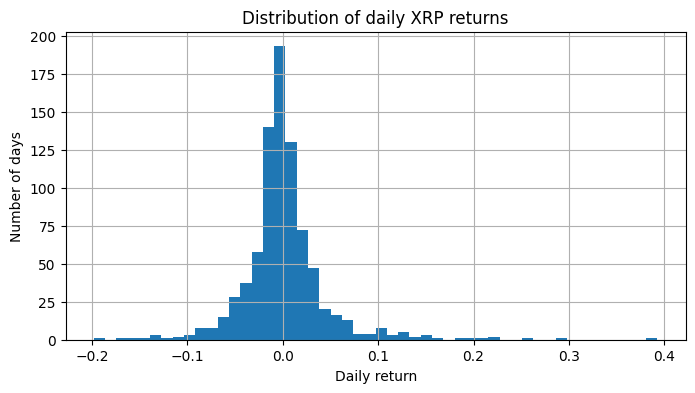

In [ ]:
dfXRP['Return'].dropna().hist(bins=50, figsize=(8, 4))
plt.title("Distribution of daily XRP returns")
plt.xlabel("Daily return")
plt.ylabel("Number of days")
plt.show()